<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/Lab_5_XAI_Ants_vs_Bees_Train_Head.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5 · Explainable AI for ResNet-18: Ants vs Bees

**One model, four questions:** *Where* in an image? *What changes the prediction?* *Which visual concepts matter across the dataset?* *Which training examples helped?*



## 1 · Setup and load the same dataset

Uses the official [PyTorch Hymenoptera dataset](https://download.pytorch.org/tutorial/hymenoptera_data.zip). If the `hymenoptera_data/` directory already exists, it is reused. **Important:** we use a fixed validation-style transform for all attribution comparisons—no random augmentation during explanation.

In [1]:
%pip -q install captum scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 11.9 MB/s eta 0:00:00


In [2]:
import copy, shutil, zipfile
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, models, transforms
from PIL import Image
from captum.attr import Saliency, Occlusion, LayerGradCam, LayerAttribution
from captum.concept import Concept, TCAV

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
root = Path('hymenoptera_data')
if not (root / 'train').exists():
    zip_path, _ = urlretrieve('https://download.pytorch.org/tutorial/hymenoptera_data.zip')
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall('.')

norm = transforms.Normalize([.485, .456, .406], [.229, .224, .225])
tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                         transforms.ToTensor(), norm])
train_ds = datasets.ImageFolder(root / 'train', transform=tf)
val_ds = datasets.ImageFolder(root / 'val', transform=tf)
classes = train_ds.classes  # ['ants', 'bees']
print(f'{classes} | train={len(train_ds)} | val={len(val_ds)} | {device}')

def show_image(ax, ds, idx, title=''):
    ax.imshow(Image.open(ds.samples[idx][0]).convert('RGB'))
    ax.set_title(title, fontsize=9); ax.axis('off')

def rgb(x):
    x = x.detach().cpu()
    mean = x.new_tensor([.485, .456, .406])[:, None, None]
    std = x.new_tensor([.229, .224, .225])[:, None, None]
    return (x * std + mean).permute(1, 2, 0).clamp(0, 1).numpy()

['ants', 'bees'] | train=244 | val=153 | cuda


## 2 · Train our own ResNet-18 classifier (quick transfer learning)

Start from **ImageNet-pretrained ResNet-18**. Freeze its convolutional backbone and **initialize a new two-class classification head**. We extract the backbone's 512-D features once, then train the new head from scratch using our own ants/bees training images. This is equivalent to fixed-feature transfer learning, but much faster than repeatedly running the CNN during each epoch.

**Every notebook run trains a fresh head:** no `xai_ants_bees_head.pt` is loaded or required. Note that the **backbone is pretrained**, not learned from scratch; only the two-class head is trained here.

In [3]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1).to(device).eval()
for p in model.parameters():
    p.requires_grad_(False)
model.fc = nn.Linear(model.fc.in_features, 2).to(device)  # new, randomly initialized head

@torch.inference_mode()
def encode(ds):
    head = model.fc
    model.fc = nn.Identity()
    features, labels = [], []
    for images, targets in DataLoader(ds, batch_size=32, shuffle=False):
        features.append(model(images.to(device)).cpu())
        labels.append(targets)
    model.fc = head
    return torch.cat(features), torch.cat(labels)

tr_features, tr_labels = encode(train_ds)
te_features, te_labels = encode(val_ds)

# Train only the classification head (no checkpoint loading).
features = tr_features.to(device)
labels = tr_labels.to(device)
val_features = te_features.to(device)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.01)

for epoch in range(1, 61):
    model.fc.train()
    optimizer.zero_grad()
    loss = F.cross_entropy(model.fc(features), labels)
    loss.backward()
    optimizer.step()
    if epoch % 15 == 0:
        model.fc.eval()
        with torch.no_grad():
            train_acc = (model.fc(features).argmax(1) == labels).float().mean()
            val_acc = (model.fc(val_features).argmax(1).cpu() == te_labels).float().mean()
        print(f'Epoch {epoch:02d} | loss={loss.item():.3f} | '
              f'train={train_acc:.1%} | val={val_acc:.1%}')

model.eval()
print('Trained parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 130MB/s]


Epoch 15 | loss=0.155 | train=95.9% | val=94.1%
Epoch 30 | loss=0.042 | train=98.4% | val=95.4%
Epoch 45 | loss=0.020 | train=99.6% | val=96.1%
Epoch 60 | loss=0.013 | train=100.0% | val=96.1%
Trained parameters: 1026


## 3 · Local XAI: gradient vs perturbation

- **Vanilla Saliency (gradient):** \( |\partial s_c / \partial x| \). Fast, pixel-resolution, often noisy; sensitivity to *small changes*, not a causal feature effect.
- **Occlusion (perturbation):** hide a **32×32 patch**, measure how much the *target logit* falls. Slower, easier to test with actual interventions; depends on the replacement baseline and patch size.
- **Grad-CAM (gradient):** gradients weight late convolutional feature maps; coarse class-oriented heatmap. Here added for comparison with Lab 4.

All explanations use **logits** (before softmax); bright overlays indicate *larger positive contribution/sensitivity under that method*.

Query 20: true=ants; predicted=ants


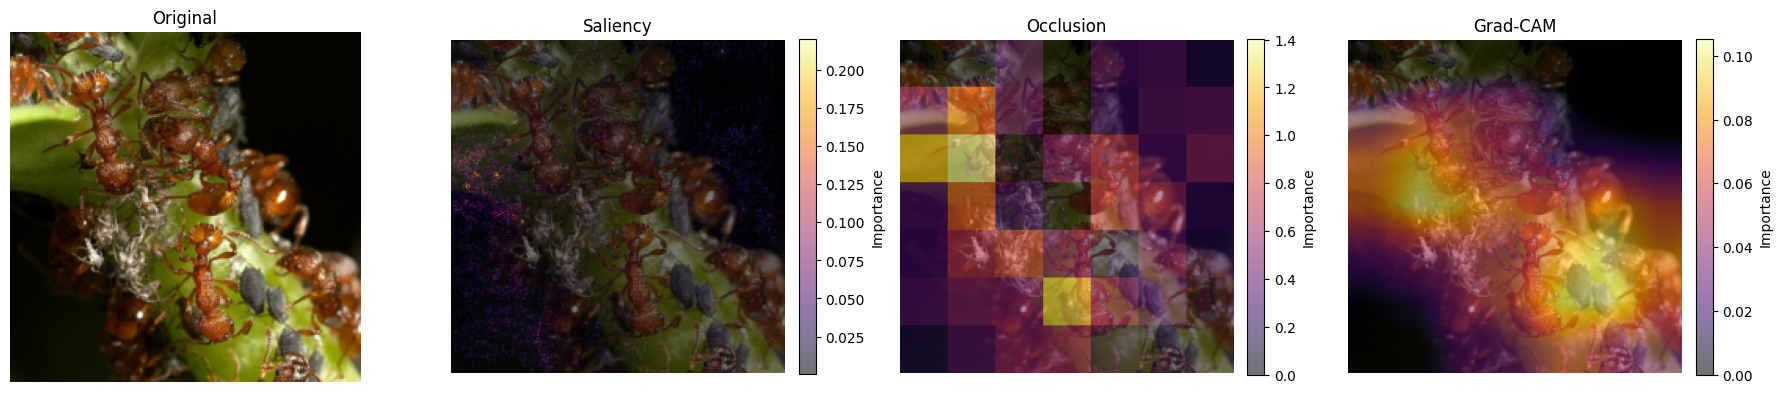

In [4]:
import random
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch.nn.functional as F

# Randomly choose one correct sample of the class
QUERY_CLASS = 'ants'
cls_id = classes.index(QUERY_CLASS)
candidates = [i for i, y in enumerate(val_ds.targets) if y == cls_id]

model = model.to(device)

with torch.no_grad():
    predictions = model.fc(te_features.to(device)).argmax(1).cpu()

correct = [i for i in candidates if int(predictions[i]) == cls_id]
QUERY_IDX = random.choice(correct or candidates)

x = val_ds[QUERY_IDX][0].unsqueeze(0).to(device).requires_grad_(True)

with torch.no_grad():
    pred = int(model(x).argmax(1).item())

print(f'Query {QUERY_IDX}: true={classes[val_ds.targets[QUERY_IDX]]}; predicted={classes[pred]}')

# XAI maps
sal = Saliency(model).attribute(x, target=pred).abs().amax(1)[0]
occ = Occlusion(model).attribute(
    x,
    target=pred,
    sliding_window_shapes=(3, 32, 32),
    strides=(3, 32, 32),
    baselines=0
).mean(1)[0]

cam = LayerGradCam(model, model.layer4[-1].conv2).attribute(x, target=pred)
cam = LayerAttribution.interpolate(
    cam,
    (224, 224),
    interpolate_mode='bilinear'
)[0, 0]

# Only keep positive values for visualization
sal_map = F.relu(sal).detach().cpu()
occ_map = F.relu(occ).detach().cpu()
cam_map = F.relu(cam).detach().cpu()

fig, ax = plt.subplots(1, 4, figsize=(18, 4))

# Original
ax[0].imshow(rgb(x[0]))
ax[0].set_title('Original')
ax[0].axis('off')

# Saliency
ax[1].imshow(rgb(x[0]))
im1 = ax[1].imshow(sal_map, cmap='inferno', alpha=0.55)
ax[1].set_title('Saliency')
ax[1].axis('off')
cbar1 = fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)
cbar1.set_label('Importance')

# Occlusion
ax[2].imshow(rgb(x[0]))
im2 = ax[2].imshow(occ_map, cmap='inferno', alpha=0.55)
ax[2].set_title('Occlusion')
ax[2].axis('off')
cbar2 = fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04)
cbar2.set_label('Importance')

# Grad-CAM
ax[3].imshow(rgb(x[0]))
im3 = ax[3].imshow(cam_map, cmap='inferno', alpha=0.55)
ax[3].set_title('Grad-CAM')
ax[3].axis('off')
cbar3 = fig.colorbar(im3, ax=ax[3], fraction=0.046, pad=0.04)
cbar3.set_label('Importance')

plt.tight_layout()
plt.show()

**Discuss:** Do different explanations select the insect or the background? Saliency measures *sensitivity*; occlusion tests a specific deletion; Grad-CAM has a coarser spatial resolution. **Do not interpret color as calibrated probability or definite causality.**

## Global XAI: TCAV (concept-based)

**TCAV** tests how sensitive a class score is to a human-defined **concept direction**, then aggregates **signs** over many examples. A sign-count score of `0.80` means **80% of queried images have positive directional sensitivity**, *not* "80% of the prediction is due to the concept."

**Using the classifier trained above:** use 24 ant images and 24 bee images as two *class-associated visual concepts*. This is deliberately a **sanity check**, not an independent claim about wings or flowers. To test **wings / flowers / background bias**, students must curate separate, background-matched concept and control image folders (suggested in tasks below). Do not label every bee as "wings" or every bee image as "flowers".

##  Which training image helped?

---



[TRAK — Attributing Model Behavior at Scale (Park et al., ICML 2023)](https://arxiv.org/abs/2303.14186). It approximates training-data attribution using **per-example gradients, random projections, and model checkpoints**. Official [TRAK quickstart](https://trak.readthedocs.io/en/latest/quickstart.html).


In [5]:
!pip install traker

  Preparing metadata (setup.py) ... done
  Created wheel for traker: filename=traker-0.3.2-py3-none-any.whl size=29030 sha256=ef2c145649aec54d00beff5cdbc4e91f543351ee5432cdd3ceafa52700473e24
  Stored in directory: /root/.cache/pip/wheels/94/5d/b7/e2e6ee7a0793141139d942c5da6ef8dd532277a97fe31e8c7c
Successfully built traker


ERROR:TRAK:Could not use CudaProjector.
Reason: No module named 'fast_jl'
ERROR:TRAK:Defaulting to BasicProjector.
INFO:STORE:No existing model IDs in /content/trak_ants_bees_demo.
INFO:STORE:No existing TRAK scores in /content/trak_ants_bees_demo.
Finalizing scores for all model IDs..: 100%|██████████| 3/3 [00:00<00:00, 307.32it/s]
INFO:STORE:Saving scores in /content/trak_ants_bees_demo/scores/bee_test.mmap


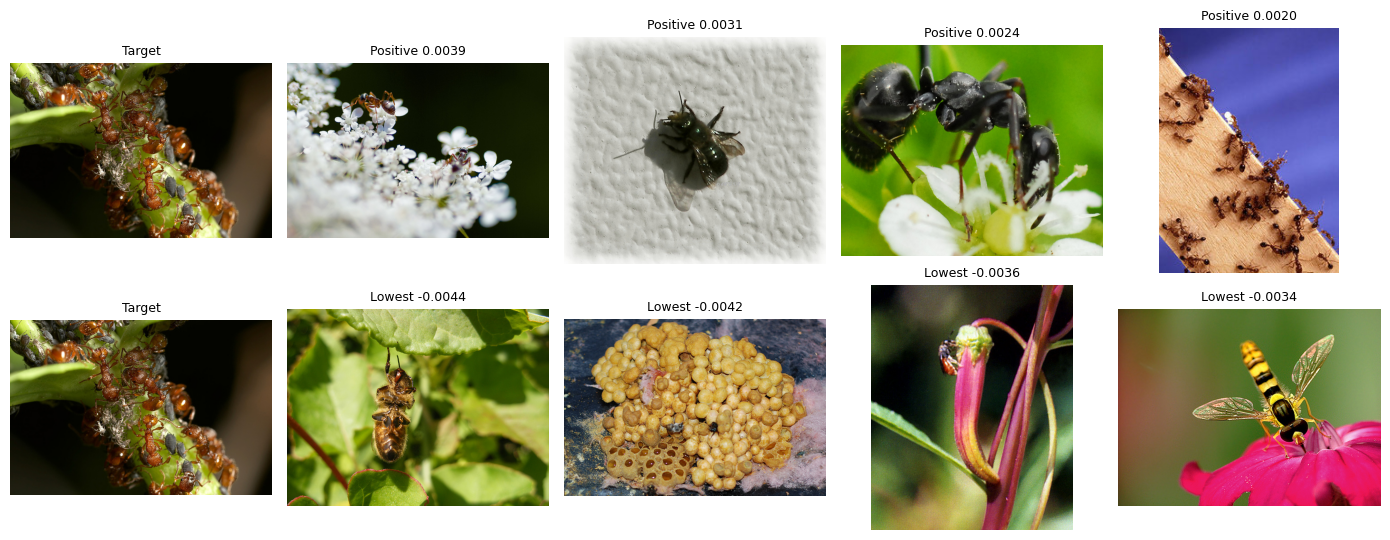

In [6]:
RUN_TRAK = True

if RUN_TRAK:
    from trak import TRAKer
    z_train = F.normalize(tr_features, dim=1).to(device)
    z_query = F.normalize(te_features[QUERY_IDX:QUERY_IDX+1], dim=1).to(device)
    train_loader = DataLoader(TensorDataset(z_train, tr_labels.to(device)), batch_size=32)
    target_loader = DataLoader(TensorDataset(z_query, te_labels[QUERY_IDX:QUERY_IDX+1].to(device)))

    checkpoints = []
    for seed in (10, 20, 30):
        torch.manual_seed(seed)
        head = nn.Linear(512, 2).to(device)
        optimizer = torch.optim.Adam(head.parameters(), lr=.02)
        for _ in range(120):
            optimizer.zero_grad()
            F.cross_entropy(head(z_train), tr_labels.to(device)).backward()
            optimizer.step()
        checkpoints.append(copy.deepcopy(head.eval().state_dict()))

    shutil.rmtree('trak_ants_bees_demo', ignore_errors=True)
    traker = TRAKer(model=nn.Linear(512, 2).to(device).eval(),
                    task='image_classification', train_set_size=len(train_ds),
                    proj_dim=64, use_half_precision=False, device=str(device),
                    save_dir='trak_ants_bees_demo')
    for model_id, checkpoint in enumerate(checkpoints):
        traker.load_checkpoint(checkpoint, model_id=model_id)
        for batch in train_loader:
            traker.featurize(batch=list(batch), num_samples=len(batch[0]))
    traker.finalize_features()
    for model_id, checkpoint in enumerate(checkpoints):
        traker.start_scoring_checkpoint(checkpoint=checkpoint, model_id=model_id,
                                        exp_name='bee_test', num_targets=1)
        for batch in target_loader:
            traker.score(batch=list(batch), num_samples=len(batch[0]))
    trak_scores = np.asarray(traker.finalize_scores(exp_name='bee_test')).reshape(-1)
    fig, ax = plt.subplots(2, 5, figsize=(14, 5.5))

    show_image(ax[0, 0], val_ds, QUERY_IDX, 'Target')
    show_image(ax[1, 0], val_ds, QUERY_IDX, 'Target')

    for a, idx in zip(ax[0, 1:], np.argsort(trak_scores)[-4:][::-1]):
        show_image(a, train_ds, int(idx), f'Positive {trak_scores[idx]:.4f}')

    for a, idx in zip(ax[1, 1:], np.argsort(trak_scores)[:4]):
        show_image(a, train_ds, int(idx), f'Lowest {trak_scores[idx]:.4f}')

    plt.tight_layout()
    plt.show()





### References

- O'Sullivan, [*Taxonomy of XAI for Computer Vision*](https://adataodyssey.com/taxonomy-of-xai/) — global/local; perturbation/gradient; post-hoc/design.
- Kim et al. (ICML 2018), [TCAV](https://proceedings.mlr.press/v80/kim18d.html).
- Selvaraju et al. (ICCV 2017), [Grad-CAM](https://arxiv.org/abs/1610.02391).
- Park et al. (ICML 2023), [TRAK](https://arxiv.org/abs/2303.14186); [official documentation](https://trak.readthedocs.io/en/latest/quickstart.html).
- Captum: [Saliency](https://captum.ai/api/saliency.html), [Occlusion](https://captum.ai/api/occlusion.html), [TCAV](https://captum.ai/tutorials/TCAV_Image).